In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.read_csv("data/train.csv")
df.shape

(691369, 14)

## Columns (inferred meaning)

- `id` — row identifier
- `age` — respondent age (years)
- `daily_screen_time_hours` — total daily screen time (hours)
- `social_media_hours` — daily time on social media (hours)
- `gaming_hours` — daily time gaming (hours)
- `work_study_hours` — daily phone time spent on work/study apps (hours) — a screen-time component, not offline work
- `sleep_hours` — daily sleep duration (hours)
- `notifications_per_day` — count of phone notifications received per day
- `app_opens_per_day` — count of app opens/unlocks per day
- `weekend_screen_time` — total screen time on weekends (hours)
- `gender` — categorical: Male/Female/Other
- `stress_level` — categorical: Low/Medium/High (self-reported)
- `academic_work_impact` — categorical Yes/No: whether phone use impacts academic/work performance
- `addicted_label` — target: 0/1 binary label for phone addiction

In [3]:
df.head()

,id,age,daily_screen_time_hours,social_media_hours,gaming_hours,work_study_hours,sleep_hours,notifications_per_day,app_opens_per_day,weekend_screen_time,gender,stress_level,academic_work_impact,addicted_label
0,0,24.0,NaN,1.83,1.59,2.11,7.46,122.0,38.0,8.63,Male,Medium,No,1
1,1,19.0,5.97,1.08,NaN,3.03,8.22,76.0,19.0,NaN,Female,Medium,No,0
2,2,18.0,5.09,NaN,NaN,NaN,6.25,134.0,60.0,7.47,Female,Low,Yes,0
3,3,21.0,6.42,1.26,1.42,3.36,8.85,112.0,94.0,8.66,Other,Low,NaN,1
4,4,26.0,11.20,1.87,2.81,1.95,5.25,NaN,NaN,13.39,Female,Medium,No,1


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 691369 entries, 0 to 691368
Data columns (total 14 columns):
 #   Column                   Non-Null Count   Dtype  
---  ------                   --------------   -----  
 0   id                       691369 non-null  int64  
 1   age                      662440 non-null  float64
 2   daily_screen_time_hours  595515 non-null  float64
 3   social_media_hours       557374 non-null  float64
 4   gaming_hours             564548 non-null  float64
 5   work_study_hours         639851 non-null  float64
 6   sleep_hours              646889 non-null  float64
 7   notifications_per_day    623785 non-null  float64
 8   app_opens_per_day        610659 non-null  float64
 9   weekend_screen_time      579306 non-null  float64
 10  gender                   662335 non-null  object 
 11  stress_level             636221 non-null  object 
 12  academic_work_impact     647145 non-null  object 
 13  addicted_label           691369 non-null  int64  
dtypes: f

In [5]:
df.describe(include="all")

,id,age,daily_screen_time_hours,social_media_hours,gaming_hours,work_study_hours,sleep_hours,notifications_per_day,app_opens_per_day,weekend_screen_time,gender,stress_level,academic_work_impact,addicted_label
count,691369.000000,662440.000000,595515.000000,557374.000000,564548.000000,639851.000000,646889.000000,623785.000000,610659.000000,579306.000000,662335,636221,647145,691369.000000
unique,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3,3,2,NaN
top,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Male,High,Yes,NaN
freq,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,223662,220873,330566,NaN
mean,345684.000000,26.615408,7.640865,2.471038,1.459265,2.366971,6.804334,145.894900,102.636781,9.479866,NaN,NaN,NaN,0.709424
std,199581.183466,5.153162,2.721446,1.316137,0.934552,1.258797,1.234512,65.917556,48.093970,2.856006,NaN,NaN,NaN,0.454028
min,0.000000,18.000000,0.500000,0.000000,0.000000,0.000000,4.500000,20.000000,15.000000,0.510000,NaN,NaN,NaN,0.000000
25%,172842.000000,22.000000,5.480000,1.450000,0.700000,1.360000,5.780000,93.000000,64.000000,7.280000,NaN,NaN,NaN,0.000000
50%,345684.000000,27.000000,7.770000,2.310000,1.330000,2.200000,6.800000,150.000000,104.000000,9.580000,NaN,NaN,NaN,1.000000
75%,518526.000000,31.000000,9.840000,3.370000,2.090000,3.200000,7.870000,204.000000,145.000000,11.750000,NaN,NaN,NaN,1.000000


## Missing data

In [6]:
missing = df.isna().sum().to_frame("n_missing")
missing["pct_missing"] = (missing["n_missing"] / len(df) * 100).round(2)
missing.sort_values("pct_missing", ascending=False)

,n_missing,pct_missing
social_media_hours,133995,19.38
gaming_hours,126821,18.34
weekend_screen_time,112063,16.21
daily_screen_time_hours,95854,13.86
app_opens_per_day,80710,11.67
notifications_per_day,67584,9.78
stress_level,55148,7.98
work_study_hours,51518,7.45
sleep_hours,44480,6.43
academic_work_impact,44224,6.40


In [20]:
rows_with_any_missing = df.isna().any(axis=1).sum()
print(f"Rows with at least 1 missing value: {rows_with_any_missing} ({rows_with_any_missing / len(df) * 100:.2f}%)")
print(f"Rows remaining after dropna(): {len(df) - rows_with_any_missing} ({(len(df) - rows_with_any_missing) / len(df) * 100:.2f}%)")

n_missing_per_row = df.isna().sum(axis=1)
n_missing_per_row.value_counts().sort_index()

Rows with at least 1 missing value: 422184 (61.06%)
Rows remaining after dropna(): 269185 (38.94%)


0     269185
1     180459
2     120697
3      67328
4      32557
5      13678
6       5157
7       1676
8        477
9        136
10        18
11         1
Name: count, dtype: int64

In [21]:
df.groupby(n_missing_per_row)["addicted_label"].agg(["mean", "count"])

,mean,count
0,0.708123,269185
1,0.708970,180459
2,0.711178,120697
3,0.711784,67328
4,0.709494,32557
5,0.712458,13678
6,0.719217,5157
7,0.696301,1676
8,0.702306,477
9,0.661765,136


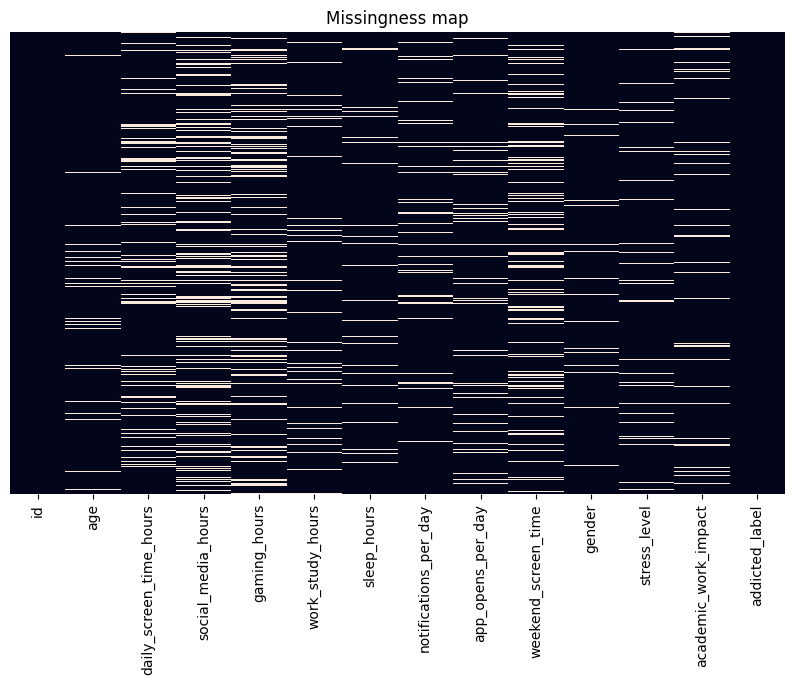

In [8]:
plt.figure(figsize=(10, 6))
sns.heatmap(df.isna(), cbar=False, yticklabels=False)
plt.title("Missingness map")
plt.show()

## Missingness vs target

Is a value missing more/less often for addicted vs non-addicted rows? Compares the addiction rate among rows where each column is missing vs where it's present.

In [16]:
cols_to_check = list(numeric_cols) + ["gender", "stress_level", "academic_work_impact"]
rows = []
for col in cols_to_check:
    is_missing = df[col].isna()
    rows.append({
        "column": col,
        "n_missing": is_missing.sum(),
        "addicted_rate_missing": df.loc[is_missing, "addicted_label"].mean(),
        "addicted_rate_present": df.loc[~is_missing, "addicted_label"].mean(),
    })
missing_vs_target = pd.DataFrame(rows).set_index("column")
missing_vs_target["diff"] = missing_vs_target["addicted_rate_missing"] - missing_vs_target["addicted_rate_present"]
missing_vs_target.sort_values("diff", key=abs, ascending=False)

,n_missing,addicted_rate_missing,addicted_rate_present,diff
column,,,,
sleep_hours,44480,0.713377,0.709153,0.004224
age,28929,0.713402,0.709251,0.004151
app_opens_per_day,80710,0.712787,0.708980,0.003807
daily_screen_time_hours,95854,0.711301,0.709122,0.002178
weekend_screen_time,112063,0.710654,0.709187,0.001467
gaming_hours,126821,0.710505,0.709182,0.001324
work_study_hours,51518,0.710645,0.709326,0.001319
notifications_per_day,67584,0.710242,0.709336,0.000906
gender,29034,0.708790,0.709452,-0.000662


## Target distribution

addicted_label
1    0.709424
0    0.290576
Name: proportion, dtype: float64


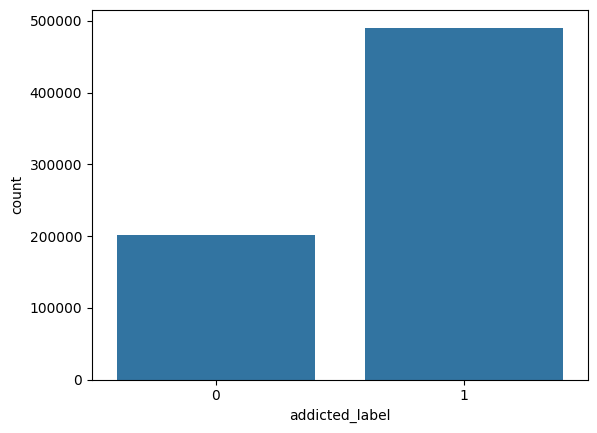

In [7]:
print(df["addicted_label"].value_counts(normalize=True))
sns.countplot(x="addicted_label", data=df)
plt.show()

## Numeric feature distributions

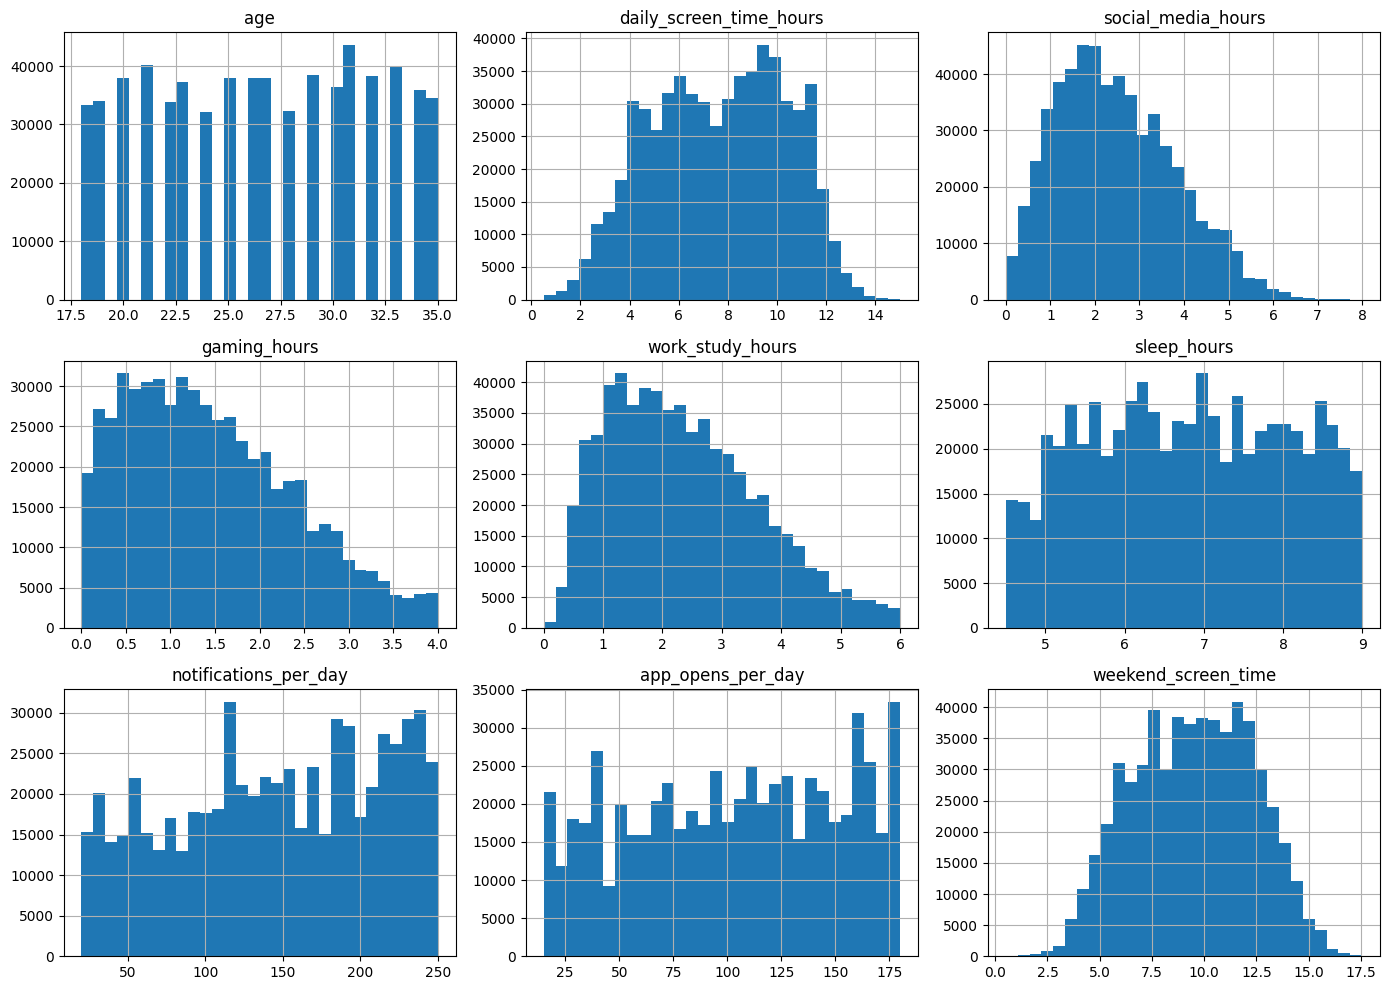

In [9]:
numeric_cols = df.select_dtypes(include="number").columns.drop(["id", "addicted_label"])
df[numeric_cols].hist(figsize=(14, 10), bins=30)
plt.tight_layout()
plt.show()

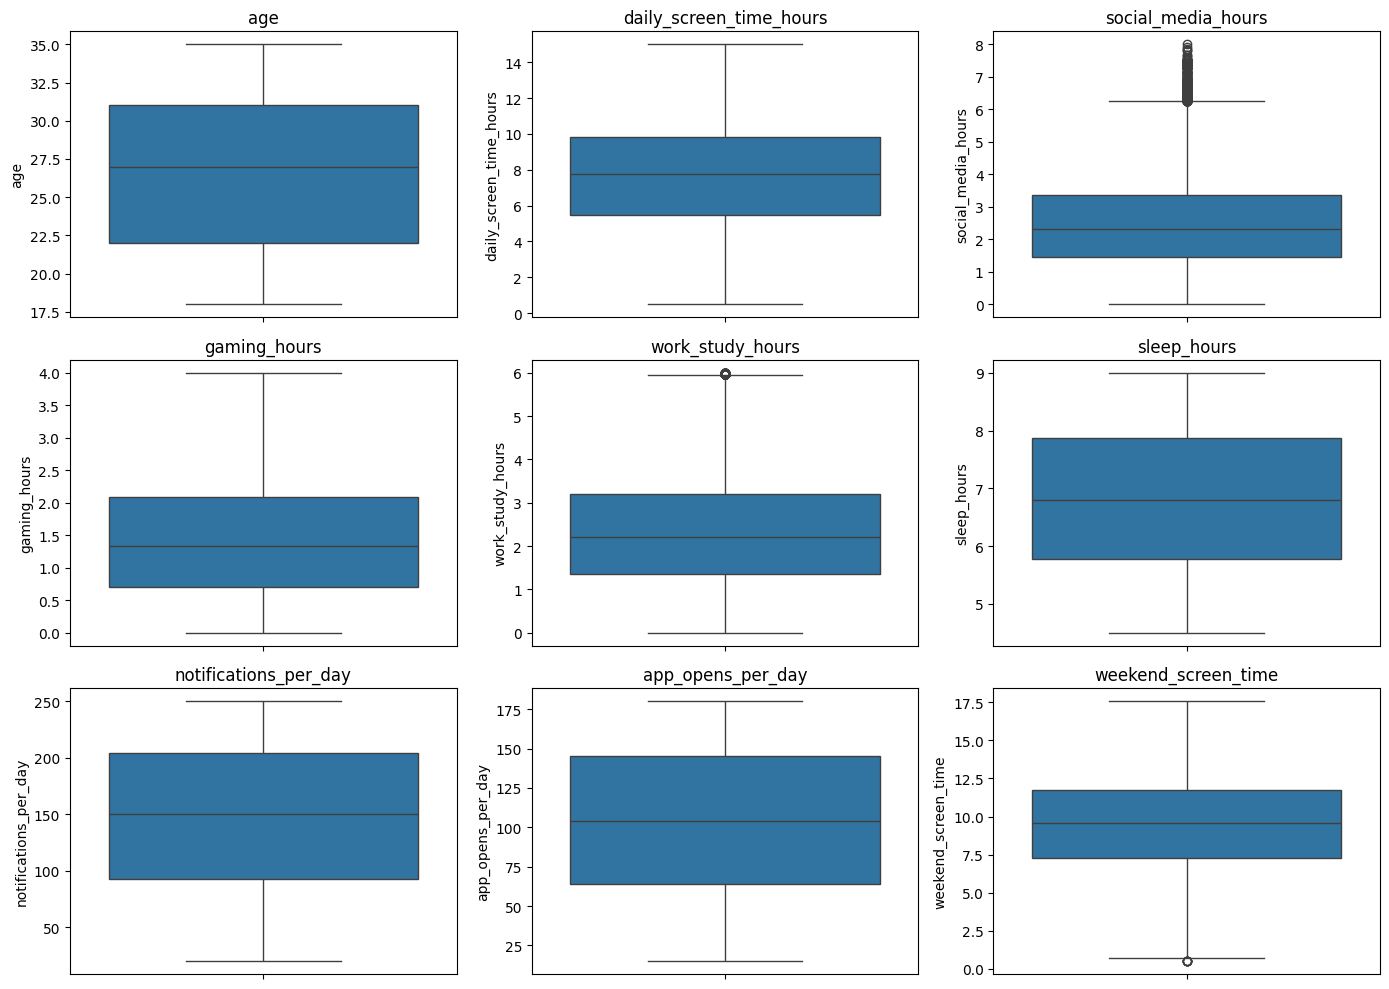

In [10]:
fig, axes = plt.subplots(3, 3, figsize=(14, 10))
for col, ax in zip(numeric_cols, axes.ravel()):
    sns.boxplot(y=df[col], ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

## Categorical feature distributions

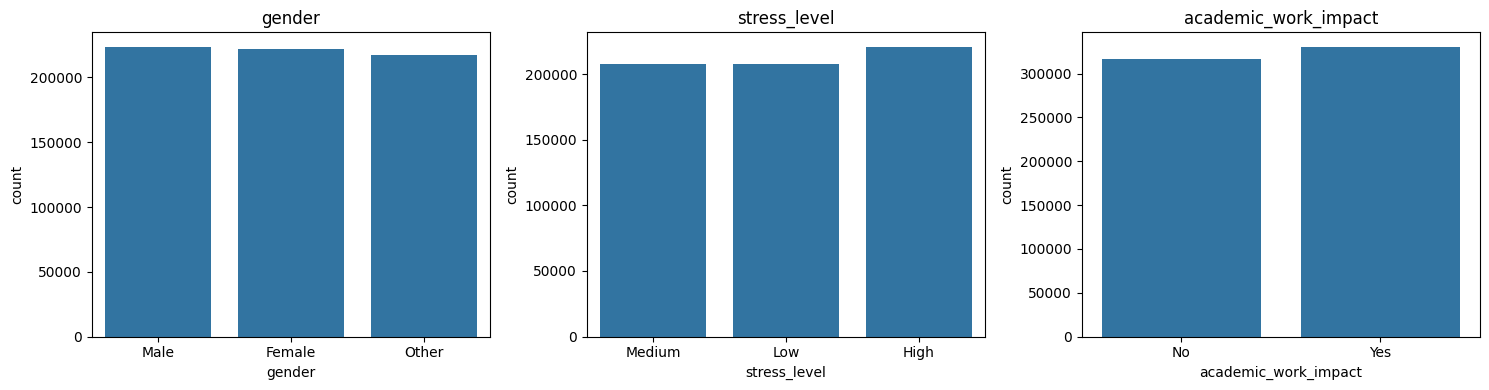

In [11]:
categorical_cols = ["gender", "stress_level", "academic_work_impact"]
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for col, ax in zip(categorical_cols, axes):
    sns.countplot(x=col, data=df, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

## Bivariate analysis vs target

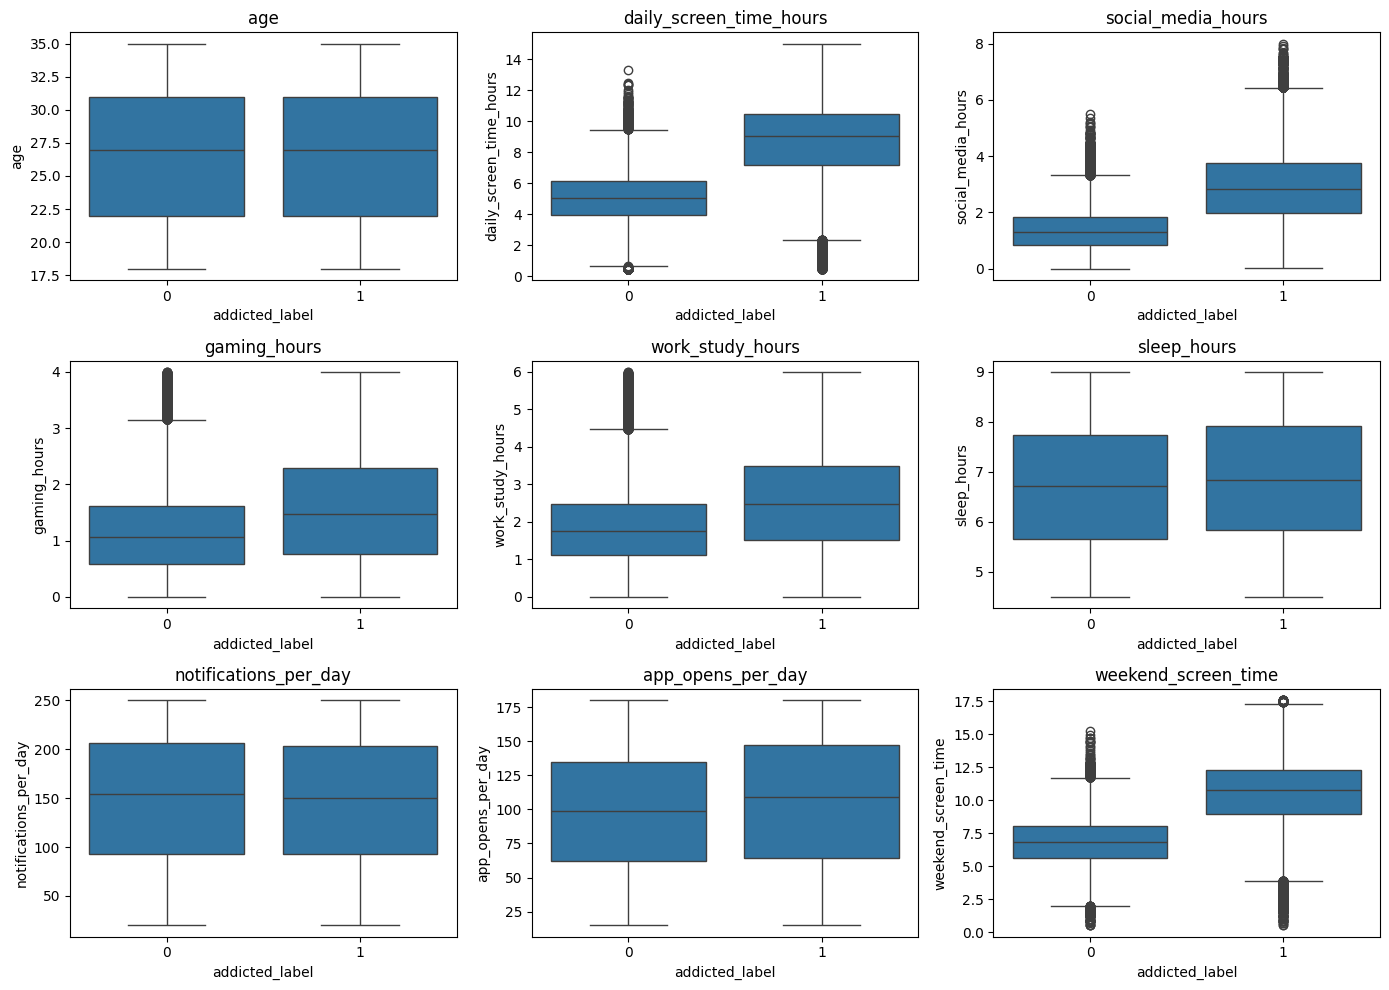

In [12]:
fig, axes = plt.subplots(3, 3, figsize=(14, 10))
for col, ax in zip(numeric_cols, axes.ravel()):
    sns.boxplot(x="addicted_label", y=col, data=df, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

addicted_label         0         1
gender                            
Female          0.296162  0.703838
Male            0.276802  0.723198
Other           0.298980  0.701020 



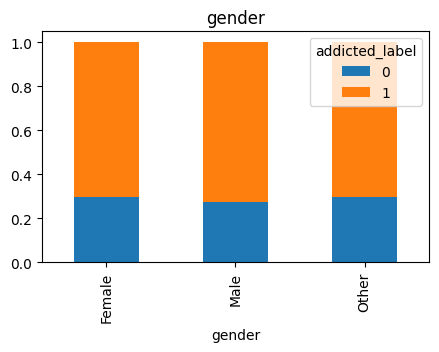

addicted_label         0         1
stress_level                      
High            0.288569  0.711431
Low             0.288840  0.711160
Medium          0.294337  0.705663 



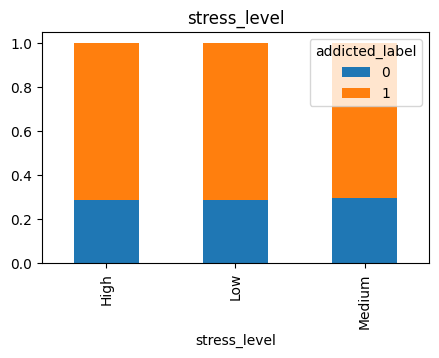

addicted_label               0         1
academic_work_impact                    
No                    0.288971  0.711029
Yes                   0.292117  0.707883 



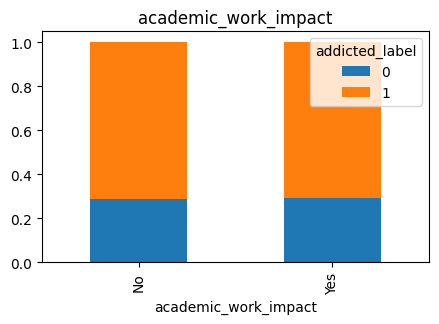

In [13]:
for col in categorical_cols:
    ct = pd.crosstab(df[col], df["addicted_label"], normalize="index")
    print(ct, "\n")
    ct.plot(kind="bar", stacked=True, figsize=(5, 3), title=col)
    plt.show()

## Correlation analysis

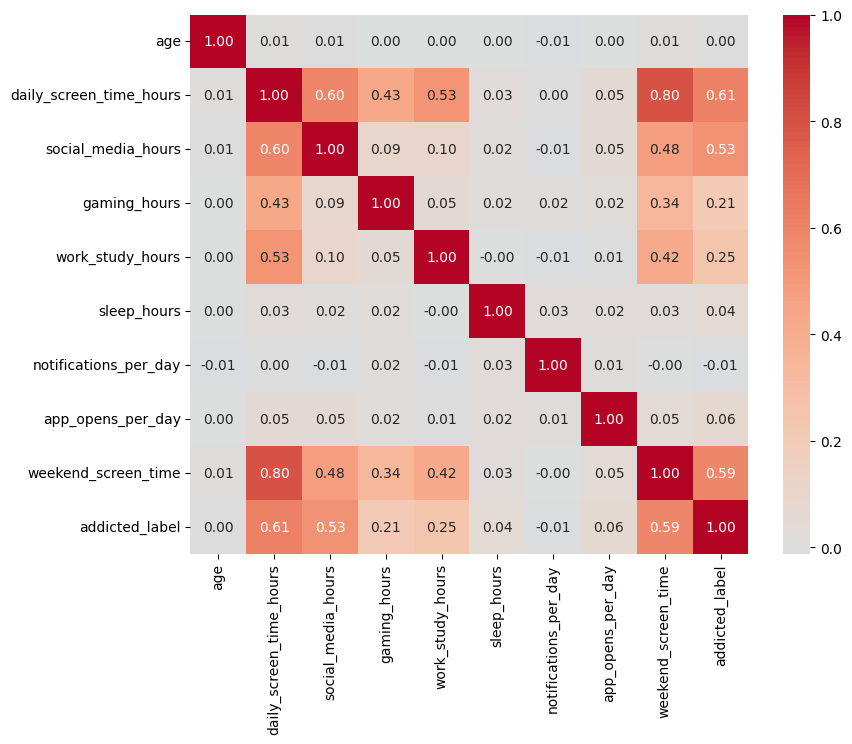

In [14]:
corr = df[list(numeric_cols) + ["addicted_label"]].corr()
plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.show()

## Feature relationships

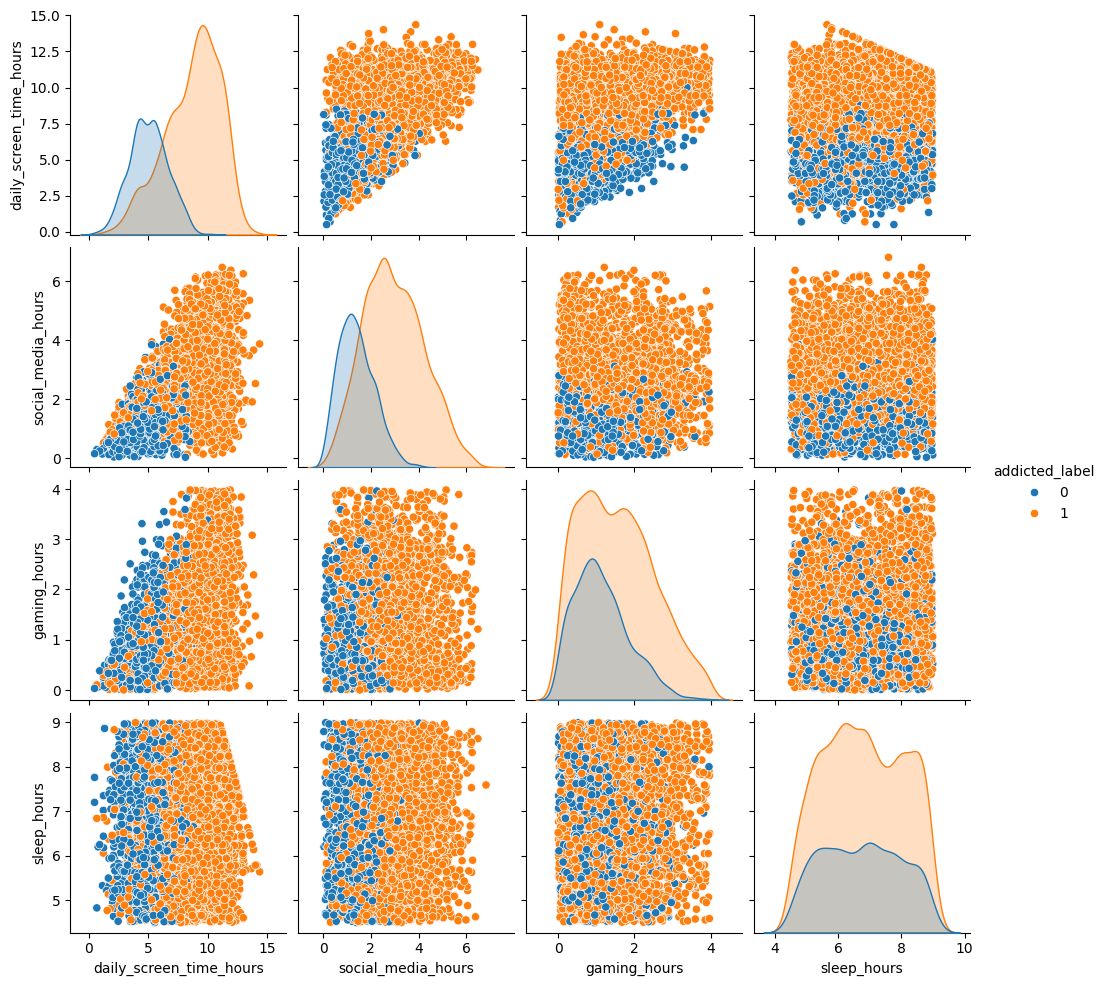

In [15]:
key_cols = ["daily_screen_time_hours", "social_media_hours", "gaming_hours", "sleep_hours", "stress_level", "addicted_label"]
sample = df[key_cols].sample(5000, random_state=42)  # sampled for plotting speed
sns.pairplot(sample, hue="addicted_label", diag_kind="kde")
plt.show()

## Binned feature distributions vs target

Addiction rate per bin, e.g. age grouped into 5-year bins.

              mean   count
age                       
(15, 20]  0.689927  105301
(20, 25]  0.709409  181437
(25, 30]  0.727468  183193
(30, 35]  0.702336  192509


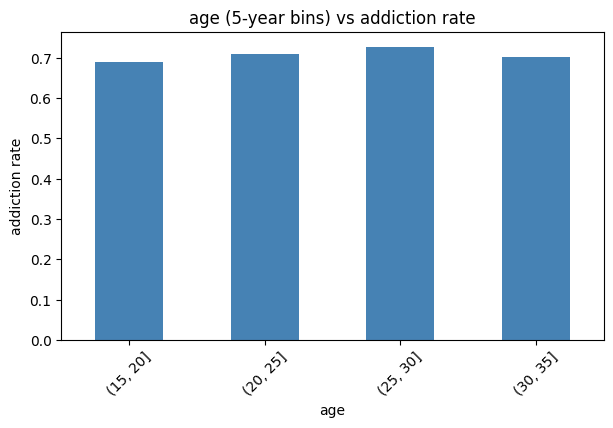

In [17]:
age_bins = pd.cut(df["age"], bins=range(15, 41, 5))
age_stats = df.groupby(age_bins, observed=True)["addicted_label"].agg(["mean", "count"])
print(age_stats)

fig, ax1 = plt.subplots(figsize=(7, 4))
age_stats["mean"].plot(kind="bar", ax=ax1, color="steelblue")
ax1.set_ylabel("addiction rate")
ax1.set_title("age (5-year bins) vs addiction rate")
plt.xticks(rotation=45)
plt.show()

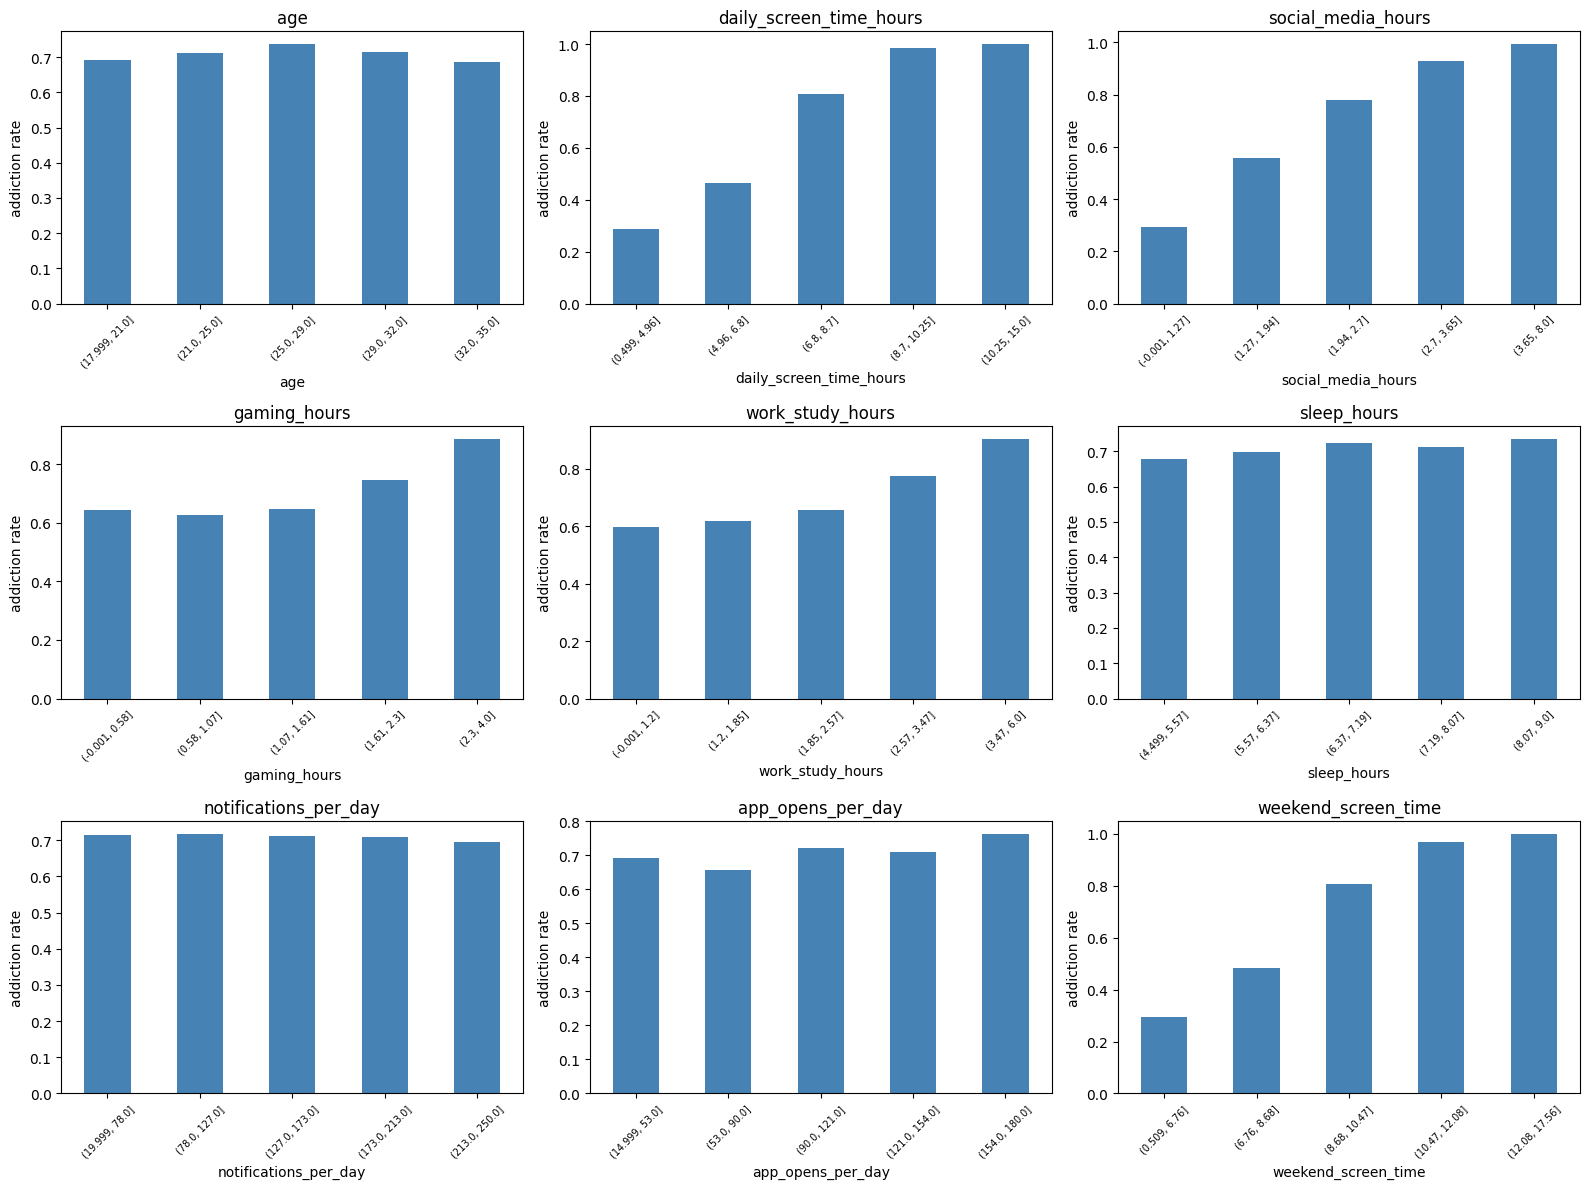

In [18]:
fig, axes = plt.subplots(3, 3, figsize=(16, 12))
for col, ax in zip(numeric_cols, axes.ravel()):
    binned = pd.qcut(df[col], q=5, duplicates="drop")  # quantile bins so each bin has similar sample size
    rate = df.groupby(binned, observed=True)["addicted_label"].mean()
    rate.plot(kind="bar", ax=ax, color="steelblue")
    ax.set_title(col)
    ax.set_ylabel("addiction rate")
    ax.tick_params(axis="x", rotation=45, labelsize=7)
plt.tight_layout()
plt.show()

## Statistical significance vs target

With ~691k rows, even tiny effects become "significant" (p < 0.05), so p-values alone aren't very informative here — pairing them with an effect size (Cramér's V for categorical, rank-biserial r for numeric) matters more.

In [22]:
from scipy import stats

def cramers_v(contingency):
    chi2 = stats.chi2_contingency(contingency)[0]
    n = contingency.sum().sum()
    r, k = contingency.shape
    return np.sqrt(chi2 / (n * (min(r, k) - 1)))

print("Categorical vs target (chi-square test):")
for col in categorical_cols:
    contingency = pd.crosstab(df[col], df["addicted_label"])
    chi2, p, dof, expected = stats.chi2_contingency(contingency)
    print(f"{col}: chi2={chi2:.2f}, p={p:.4g}, Cramer's V={cramers_v(contingency):.4f}")

Categorical vs target (chi-square test):
gender: chi2=313.79, p=7.257e-69, Cramer's V=0.0218
stress_level: chi2=21.59, p=2.046e-05, Cramer's V=0.0058
academic_work_impact: chi2=7.75, p=0.005366, Cramer's V=0.0035


In [23]:
def rank_biserial(group0, group1, u_stat):
    n0, n1 = len(group0), len(group1)
    return 1 - (2 * u_stat) / (n0 * n1)

print("Numeric vs target (Mann-Whitney U test):")
for col in numeric_cols:
    group0 = df.loc[df["addicted_label"] == 0, col].dropna()
    group1 = df.loc[df["addicted_label"] == 1, col].dropna()
    u_stat, p = stats.mannwhitneyu(group0, group1)
    effect = rank_biserial(group0, group1, u_stat)
    print(f"{col}: p={p:.4g}, rank-biserial r={effect:.4f}")

Numeric vs target (Mann-Whitney U test):
age: p=0.003578, rank-biserial r=0.0045
daily_screen_time_hours: p=0, rank-biserial r=0.7791
social_media_hours: p=0, rank-biserial r=0.7156
gaming_hours: p=0, rank-biserial r=0.2439
work_study_hours: p=0, rank-biserial r=0.3098
sleep_hours: p=6.246e-255, rank-biserial r=0.0539
notifications_per_day: p=1.685e-22, rank-biserial r=-0.0157
app_opens_per_day: p=0, rank-biserial r=0.0818
weekend_screen_time: p=0, rank-biserial r=0.7620


## Consistency / sanity checks

Look for impossible values and logical inconsistencies between related hour-based columns.

In [24]:
# negative values shouldn't exist for any of these hour/count columns
print("Negative values per column:")
print((df[numeric_cols] < 0).sum())

print("\nOut-of-range checks:")
print(f"daily_screen_time_hours > 24: {(df['daily_screen_time_hours'] > 24).sum()}")
print(f"weekend_screen_time > 24: {(df['weekend_screen_time'] > 24).sum()}")
print(f"sleep_hours > 24: {(df['sleep_hours'] > 24).sum()}")

Negative values per column:
age                        0
daily_screen_time_hours    0
social_media_hours         0
gaming_hours               0
work_study_hours           0
sleep_hours                0
notifications_per_day      0
app_opens_per_day          0
weekend_screen_time        0
dtype: int64

Out-of-range checks:
daily_screen_time_hours > 24: 0
weekend_screen_time > 24: 0
sleep_hours > 24: 0


In [32]:
# does social media + gaming + work/study exceed (or roughly match) the reported total daily screen time?
check_cols = ["social_media_hours", "gaming_hours", "work_study_hours", "daily_screen_time_hours"]
has_all_values = df[check_cols].notna().all(axis=1)
print(f"Rows excluded (null in one of {check_cols}): {(~has_all_values).sum()} ({(~has_all_values).mean() * 100:.2f}%)")

screen_components = df.loc[has_all_values, "social_media_hours"] + df.loc[has_all_values, "gaming_hours"] + df.loc[has_all_values, "work_study_hours"]
inconsistent = screen_components > df.loc[has_all_values, "daily_screen_time_hours"]
print(f"Rows where social_media_hours + gaming_hours + work_study_hours > daily_screen_time_hours: "
      f"{inconsistent.sum()} ({inconsistent.mean() * 100:.2f}%)")
(df.loc[has_all_values, "daily_screen_time_hours"] - screen_components).describe()

Rows excluded (null in one of ['social_media_hours', 'gaming_hours', 'work_study_hours', 'daily_screen_time_hours']): 269942 (39.04%)
Rows where social_media_hours + gaming_hours + work_study_hours > daily_screen_time_hours: 0 (0.00%)


count    421427.000000
mean          1.342654
std           1.480499
min           0.000000
25%           0.460000
50%           0.750000
75%           1.460000
max          11.530000
dtype: float64

In [33]:
# is the reported day budget (screen time + sleep) plausible within 24h?
# work_study_hours is a component of daily_screen_time_hours, not added separately
has_all_values = df[["daily_screen_time_hours", "sleep_hours"]].notna().all(axis=1)
print(f"Rows excluded (null daily_screen_time_hours or sleep_hours): {(~has_all_values).sum()} ({(~has_all_values).mean() * 100:.2f}%)")

total_day_hours = df.loc[has_all_values, "daily_screen_time_hours"] + df.loc[has_all_values, "sleep_hours"]
over_24 = total_day_hours > 24
print(f"Rows where daily_screen_time_hours + sleep_hours > 24h: "
      f"{over_24.sum()} ({over_24.mean() * 100:.2f}%)")
total_day_hours.describe()

Rows excluded (null daily_screen_time_hours or sleep_hours): 132019 (19.10%)
Rows where daily_screen_time_hours + sleep_hours > 24h: 0 (0.00%)


count    559350.000000
mean         14.442555
std           3.018307
min           5.020000
25%          12.140000
50%          14.510000
75%          16.790000
max          20.010000
dtype: float64

## Missingness pattern clustering

Does missing-ness in one column tend to co-occur with missing-ness in another (e.g. a whole survey section skipped together), rather than being independent per column?

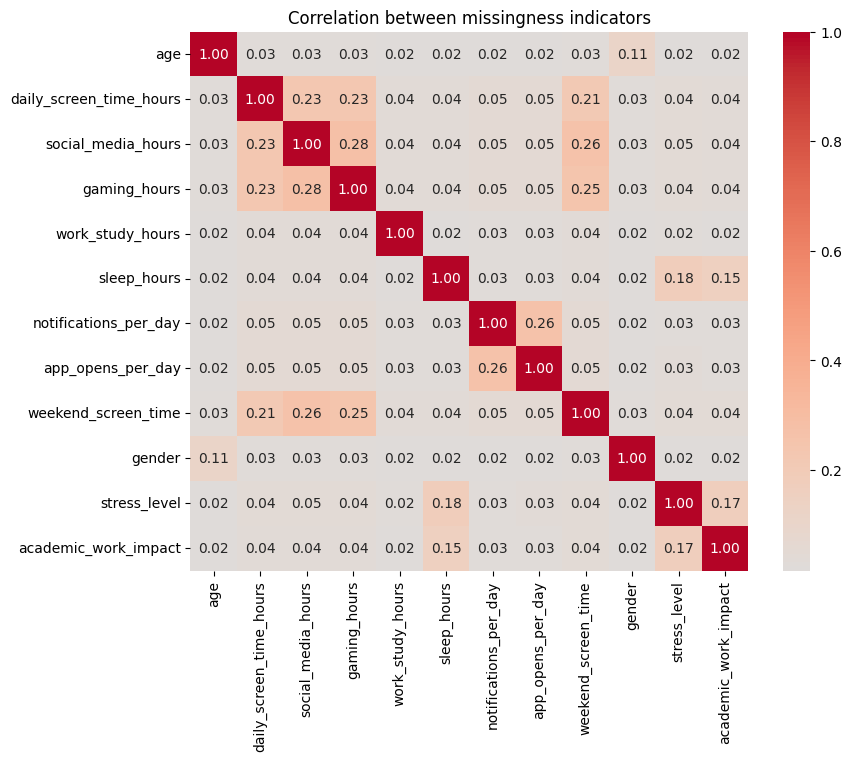

In [27]:
missing_corr = df[cols_to_check].isna().corr()
plt.figure(figsize=(9, 7))
sns.heatmap(missing_corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation between missingness indicators")
plt.show()

## Summary of findings

**Dataset**: 691,369 rows, 14 columns (9 numeric, 3 categorical, 1 target). No duplicate `id` issues.

**Target (`addicted_label`)**: imbalanced, ~71% positive (1) vs ~29% negative (0).

**Missing data**: every feature has some missingness (4%–19%), heaviest in `social_media_hours` (19.4%), `gaming_hours` (18.3%), `weekend_screen_time` (16.2%). Comparing addiction rate for missing vs present rows per column showed differences of at most ~0.4 percentage points — missingness does **not** appear informative (looks like it's missing at random, not tied to the label).

**Strongest signal features**: `daily_screen_time_hours`, `social_media_hours`, and `weekend_screen_time` show a clear, near-monotonic increase in addiction rate across their quantile bins (roughly 0.3 → 1.0 from lowest to highest bin), and have the highest correlation with the target among numeric features. These three are also highly correlated with each other (e.g. `daily_screen_time_hours` vs `weekend_screen_time` ≈ 0.80), so they carry overlapping information — worth watching for multicollinearity in linear models.

**Weak/flat signal features**: `age`, `sleep_hours`, and `notifications_per_day` show little variation in addiction rate across their bins/boxplots. Age specifically has no clear monotonic trend (0.69 → 0.71 → 0.73 → 0.70 across 5-year bins).

**Categorical features**: `gender`, `stress_level`, and `academic_work_impact` all show addiction rates clustered tightly around 0.70–0.72 across their categories — little separating power on their own.

**Implications for modeling**:
- Class imbalance (71/29) means accuracy alone will be misleading; track precision/recall/PR-AUC alongside ROC-AUC.
- Missing values likely need imputation (not row-dropping, given the volume), and since missingness isn't informative, a "missing indicator" feature is unlikely to help.
- Screen-time-related features are the main drivers of signal; categorical features and age contribute comparatively little on their own — interactions between features may be worth exploring beyond this EDA.

## Feature ranking (univariate effect size)

Ranked by univariate effect size magnitude (rank-biserial r for numeric, Cramér's V for categorical) — a first guess at importance before checking a multivariate model below.

| Rank | Feature | Effect size | Verdict |
|---|---|---|---|
| 1 | `daily_screen_time_hours` | r = 0.779 | Keep — strongest signal |
| 2 | `weekend_screen_time` | r = 0.762 | Keep — but ~0.80 correlated with #1, redundant info |
| 3 | `social_media_hours` | r = 0.716 | Keep — also correlated with #1/#2 |
| 4 | `work_study_hours` | r = 0.310 | Keep — moderate, independent-ish signal |
| 5 | `gaming_hours` | r = 0.244 | Keep — moderate signal |
| 6 | `app_opens_per_day` | r = 0.082 | Keep — weak but real, cheap to include |
| 7 | `gender` | V = 0.022 | Borderline — very weak, keep for now |
| 8 | `sleep_hours` | r = 0.054 | Borderline — weak, but plausible interaction with screen time |
| 9 | `notifications_per_day` | r = -0.016 | Candidate to skip |
| 10 | `stress_level` | V = 0.006 | Candidate to skip |
| 11 | `age` | r = 0.0045 | Candidate to skip |
| 12 | `academic_work_impact` | V = 0.0035 | Candidate to skip |

Univariate rankings can't see interaction effects, so this is only a starting guess — the tree model below gives a multivariate cross-check.

## Feature importance via tree model

Train an XGBoost classifier (handles missing values and categorical features natively, so no imputation/encoding needed) and compare two importance measures:
- **Gain**: how much each feature reduces loss when split on — can be biased toward high-cardinality/continuous features.
- **Permutation importance**: drop in test ROC-AUC when a feature's values are shuffled — more directly reflects real predictive contribution, and captures interaction effects that the earlier univariate tests couldn't.

In [34]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score
from xgboost import XGBClassifier

feature_cols = list(numeric_cols) + categorical_cols
X = df[feature_cols].copy()
for col in categorical_cols:
    X[col] = X[col].astype("category")
y = df["addicted_label"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

model = XGBClassifier(
    n_estimators=300,
    max_depth=5,
    learning_rate=0.05,
    tree_method="hist",
    enable_categorical=True,
    importance_type="gain",
    eval_metric="logloss",
    random_state=42,
)
model.fit(X_train, y_train)

test_auc = roc_auc_score(y_test, model.predict_proba(X_test)[:, 1])
print(f"Test ROC-AUC: {test_auc:.4f}")

Test ROC-AUC: 0.9496


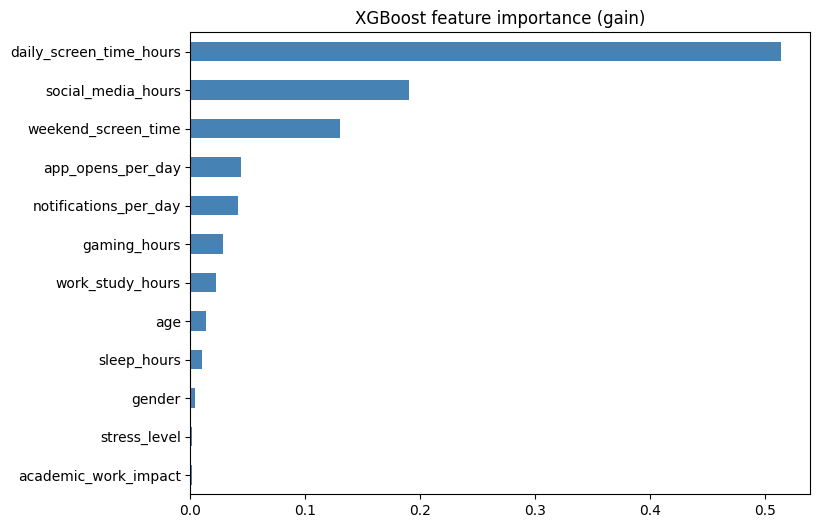

daily_screen_time_hours    0.513752
social_media_hours         0.189738
weekend_screen_time        0.130512
app_opens_per_day          0.044197
notifications_per_day      0.041095
gaming_hours               0.027974
work_study_hours           0.022526
age                        0.013903
sleep_hours                0.009749
gender                     0.003507
stress_level               0.001592
academic_work_impact       0.001455
dtype: float32

In [35]:
gain_importance = pd.Series(model.feature_importances_, index=feature_cols).sort_values(ascending=False)
gain_importance.plot(kind="barh", figsize=(8, 6), color="steelblue")
plt.gca().invert_yaxis()
plt.title("XGBoost feature importance (gain)")
plt.show()
gain_importance

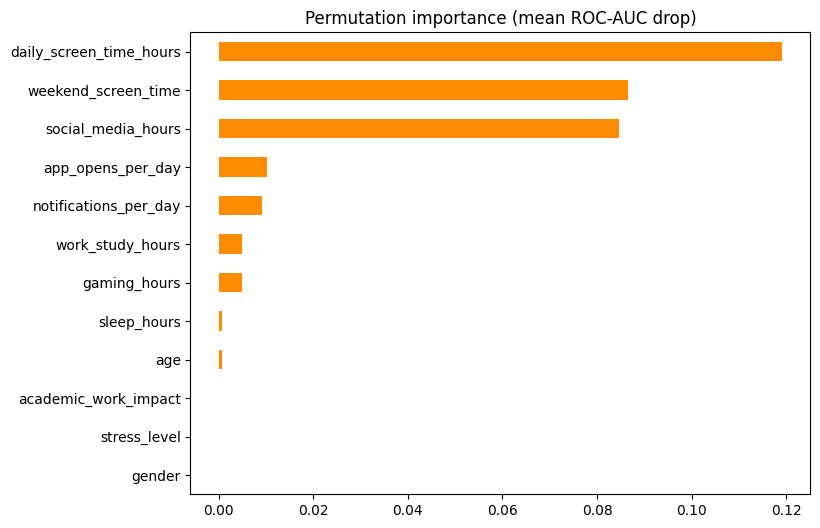

daily_screen_time_hours    1.191774e-01
weekend_screen_time        8.652939e-02
social_media_hours         8.464279e-02
app_opens_per_day          1.027653e-02
notifications_per_day      9.166288e-03
work_study_hours           5.021156e-03
gaming_hours               4.832738e-03
sleep_hours                6.866343e-04
age                        6.662826e-04
academic_work_impact       9.441033e-07
stress_level              -4.813314e-07
gender                    -8.364095e-06
dtype: float64

In [36]:
from sklearn.inspection import permutation_importance

perm = permutation_importance(model, X_test, y_test, scoring="roc_auc", n_repeats=10, random_state=42, n_jobs=-1)
perm_importance = pd.Series(perm.importances_mean, index=feature_cols).sort_values(ascending=False)
perm_importance.plot(kind="barh", figsize=(8, 6), color="darkorange")
plt.gca().invert_yaxis()
plt.title("Permutation importance (mean ROC-AUC drop)")
plt.show()
perm_importance

## Features probably valid to drop

Confirmed by two independent methods (univariate effect size and permutation importance both agree these carry ~no signal):

- `age` — rank-biserial r = 0.0045, permutation importance ≈ 0.0007
- `gender` — Cramér's V = 0.0218, permutation importance ≈ -0.00001 (negative — pure noise)
- `stress_level` — Cramér's V = 0.0058, permutation importance ≈ -0.0000005 (negative — pure noise)
- `academic_work_impact` — Cramér's V = 0.0035, permutation importance ≈ 0.0000009 (essentially zero)

`sleep_hours` is a borderline case: weak univariate effect (r = 0.054) but drops to near-zero in permutation importance (≈ 0.0007) — its marginal signal looks like overlap with the screen-time features rather than independent information, so it's also a reasonable drop candidate.

Everything else (`daily_screen_time_hours`, `weekend_screen_time`, `social_media_hours`, `work_study_hours`, `gaming_hours`, `app_opens_per_day`, `notifications_per_day`) showed meaningful contribution in at least one of the two importance measures and should be kept.

## Engineered features

Combinations built from the existing columns, each meant to capture something the raw values can't express on their own:

| Feature | Formula | Meaning |
|---|---|---|
| `social_share` | `social_media_hours / daily_screen_time_hours` | fraction of screen time spent on social media |
| `gaming_share` | `gaming_hours / daily_screen_time_hours` | fraction of screen time spent gaming |
| `study_share` | `work_study_hours / daily_screen_time_hours` | fraction of screen time spent on work/study apps |
| `opens_per_hour` | `app_opens_per_day / daily_screen_time_hours` | checking frequency per hour of use — fragmented/compulsive checking vs. long continuous sessions |
| `screen_sleep_ratio` | `daily_screen_time_hours / sleep_hours` | combined risk indicator — high when screen time is high *and* sleep is low at the same time |
| `weekend_vs_weekday` | `weekend_screen_time - 2 * daily_screen_time_hours` | weekend usage spike vs. two weekday-equivalent hours (assumes `weekend_screen_time` is a 2-day total) |
| `unaccounted_screen_time` | `daily_screen_time_hours - (social_media_hours + gaming_hours + work_study_hours)` | screen time not attributed to the three tracked activities (browsing, messaging, other apps) |
| `non_screen_awake_hours` | `24 - sleep_hours - daily_screen_time_hours` | hours in the day neither asleep nor on the phone |
| `notifications_per_open` | `notifications_per_day / app_opens_per_day` | whether opens are notification-driven vs. self-initiated/compulsive |

Retrain with all of these added at once, then check overall test ROC-AUC and per-feature permutation importance to see which ones actually add value.

In [37]:
X_eng = df[feature_cols].copy()
for col in categorical_cols:
    X_eng[col] = X_eng[col].astype("category")

# ratios/differences can divide by 0 -> inf; treat those as missing rather than a real signal
with np.errstate(divide="ignore", invalid="ignore"):
    X_eng["social_share"] = df["social_media_hours"] / df["daily_screen_time_hours"]
    X_eng["gaming_share"] = df["gaming_hours"] / df["daily_screen_time_hours"]
    X_eng["study_share"] = df["work_study_hours"] / df["daily_screen_time_hours"]
    X_eng["opens_per_hour"] = df["app_opens_per_day"] / df["daily_screen_time_hours"]
    X_eng["screen_sleep_ratio"] = df["daily_screen_time_hours"] / df["sleep_hours"]
    X_eng["notifications_per_open"] = df["notifications_per_day"] / df["app_opens_per_day"]
X_eng["weekend_vs_weekday"] = df["weekend_screen_time"] - 2 * df["daily_screen_time_hours"]
X_eng["unaccounted_screen_time"] = df["daily_screen_time_hours"] - (df["social_media_hours"] + df["gaming_hours"] + df["work_study_hours"])
X_eng["non_screen_awake_hours"] = 24 - df["sleep_hours"] - df["daily_screen_time_hours"]
X_eng = X_eng.replace([np.inf, -np.inf], np.nan)

eng_feature_cols = list(X_eng.columns)
Xe_train, Xe_test, ye_train, ye_test = train_test_split(X_eng, y, test_size=0.2, stratify=y, random_state=42)

eng_model = XGBClassifier(
    n_estimators=300,
    max_depth=5,
    learning_rate=0.05,
    tree_method="hist",
    enable_categorical=True,
    importance_type="gain",
    eval_metric="logloss",
    random_state=42,
)
eng_model.fit(Xe_train, ye_train)

eng_test_auc = roc_auc_score(ye_test, eng_model.predict_proba(Xe_test)[:, 1])
print(f"Baseline test ROC-AUC: {test_auc:.4f}")
print(f"With engineered features test ROC-AUC: {eng_test_auc:.4f}")

Baseline test ROC-AUC: 0.9496
With engineered features test ROC-AUC: 0.9529


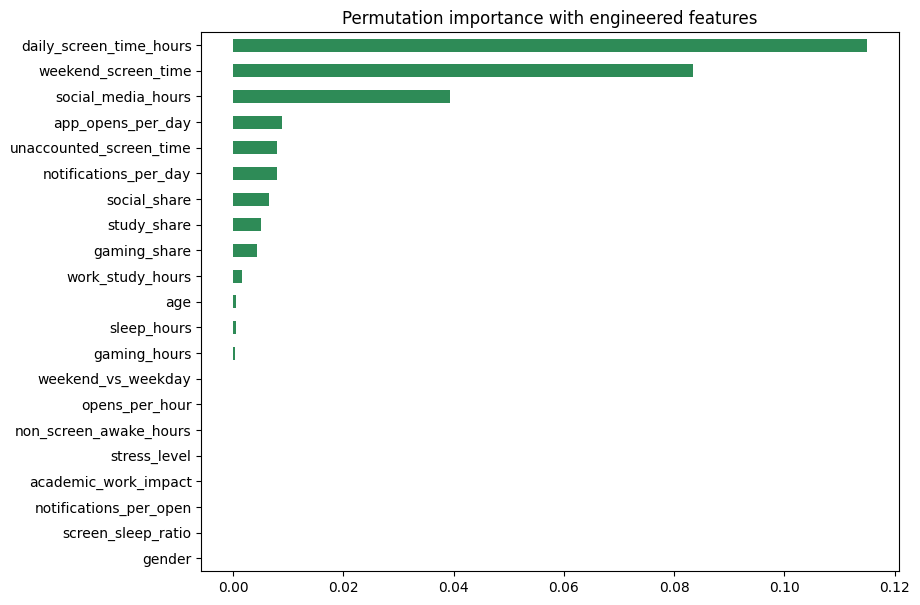

daily_screen_time_hours    1.149997e-01
weekend_screen_time        8.342399e-02
social_media_hours         3.941940e-02
app_opens_per_day          8.857673e-03
unaccounted_screen_time    8.032260e-03
notifications_per_day      7.922381e-03
social_share               6.500862e-03
study_share                5.132303e-03
gaming_share               4.258841e-03
work_study_hours           1.531501e-03
age                        5.729065e-04
sleep_hours                5.370995e-04
gaming_hours               4.309320e-04
weekend_vs_weekday         4.005160e-05
opens_per_hour             2.655344e-05
non_screen_awake_hours     6.307190e-06
stress_level               7.364338e-07
academic_work_impact      -1.163051e-07
notifications_per_open    -6.148133e-07
screen_sleep_ratio        -2.534101e-06
gender                    -3.510680e-06
dtype: float64

In [38]:
eng_perm = permutation_importance(eng_model, Xe_test, ye_test, scoring="roc_auc", n_repeats=10, random_state=42, n_jobs=-1)
eng_perm_importance = pd.Series(eng_perm.importances_mean, index=eng_feature_cols).sort_values(ascending=False)
eng_perm_importance.plot(kind="barh", figsize=(9, 7), color="seagreen")
plt.gca().invert_yaxis()
plt.title("Permutation importance with engineered features")
plt.show()
eng_perm_importance

## Engineered feature results

Test ROC-AUC: 0.9496 (baseline) → 0.9529 with engineered features — a real, modest improvement.

**Actually useful** (meaningful permutation importance):
- `unaccounted_screen_time` — screen time not explained by tracked activities
- `social_share`, `study_share`, `gaming_share` — activity composition ratios

Note `social_media_hours`'s own importance dropped from 0.085 → 0.039 once `social_share` was added — the two are sharing credit for overlapping information, exactly the correlation effect discussed earlier. The *combined* signal from `social_media_hours` + `social_share` is larger than `social_media_hours` alone contributed in the baseline, so `social_share` is adding something real, not just borrowing.

**Not useful** (~0 or negative permutation importance): `weekend_vs_weekday`, `opens_per_hour`, `non_screen_awake_hours`, `notifications_per_open`, `screen_sleep_ratio` — these ideas didn't pan out; the tree model doesn't need them to express what they encode.